# Task 1 Remaining — Spatial Analysis and Aggregation

## Data Input

This task uses the cleaned and preprocessed dataset generated in Task 1.

The dataset includes:
- Filtered trip records (invalid values removed)
- Computed trip duration, distance, and speed
- Consolidated data from all 12 months of 2025

In [1]:
import pandas as pd

df = pd.read_csv("citi_bike_2025_cleaned_consolidated.csv")

print("Dataset loaded.")
print("Rows:", len(df))
df.head()

Dataset loaded.
Rows: 998234


,ride_id,rideable_type,started_at,ended_at,trip_duration_sec,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,distance_km,speed_kmh,member_casual,source_file
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,371.574,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,1.369339,13.266861,member,JC-202501-citibike-tripdata.csv
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,687.681,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,2.862713,14.986259,member,JC-202501-citibike-tripdata.csv
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,1282.657,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,6.618233,member,JC-202501-citibike-tripdata.csv
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,1376.060,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,6.169006,member,JC-202501-citibike-tripdata.csv
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,1549.326,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,5.479107,member,JC-202501-citibike-tripdata.csv


In [2]:
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

In [3]:
station_demand = df.groupby([
    "start_station_id",
    "start_station_name",
    "start_lat",
    "start_lng"
]).size().reset_index(name="trip_count")

In [4]:
import geopandas as gpd

In [5]:
stations_gdf = gpd.GeoDataFrame(
    station_demand,
    geometry=gpd.points_from_xy(
        station_demand["start_lng"],
        station_demand["start_lat"]
    ),
    crs="EPSG:4326"
)

In [6]:
import matplotlib.pyplot as plt

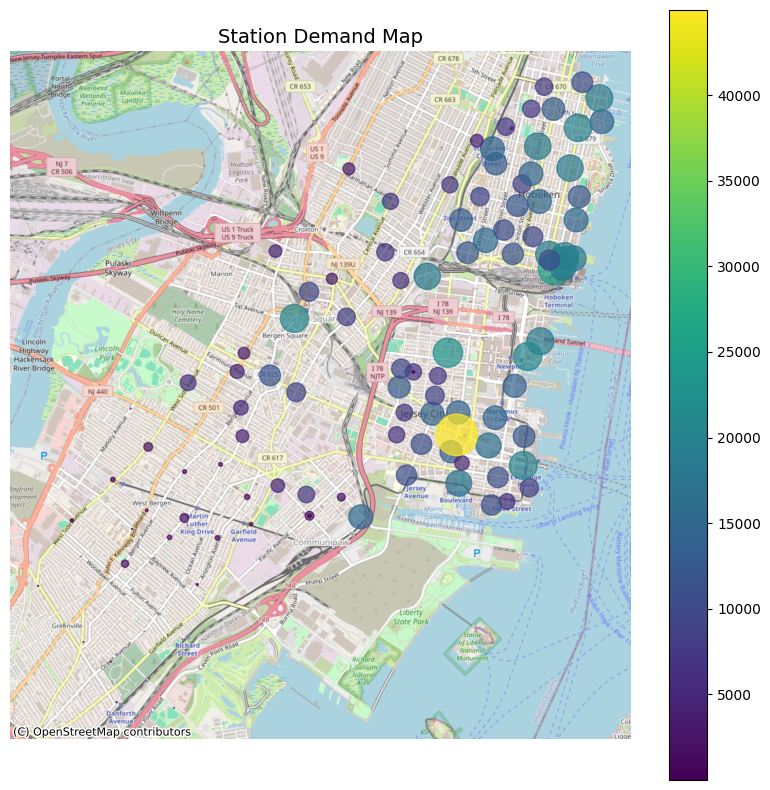

In [7]:
import matplotlib.pyplot as plt
import contextily as ctx

# Convert to Web Mercator (REQUIRED for basemap)
stations_web = stations_gdf.to_crs(epsg=3857)

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))

# Plot stations
stations_web.plot(
    ax=ax,
    column="trip_count",
    cmap="viridis",
    markersize=stations_web["trip_count"] / 50,
    alpha=0.7,
    legend=True
)


# Add basemap tiles
ctx.add_basemap(
    ax,
    source=ctx.providers.OpenStreetMap.Mapnik
)

# Final formatting
ax.set_title("Station Demand Map", fontsize=14)
ax.axis("off")

plt.show()

## Conclusion

The station demand map provides geographic context for trip activity. 
Higher-demand stations are visible in central urban areas, though patterns 
reflect both station placement and user behavior rather than pure spatial clustering.

# Task 2 — Routing

## Objective

In Task 1, the Citi Bike dataset was cleaned and prepared for further analysis. However, the dataset only contains trip origins and destinations, not the actual trajectories followed between those points.

The objective of this task is therefore to approximate trip trajectories by routing origin–destination pairs through a bicycle network derived from OpenStreetMap.

This task focuses on:

- generating route geometries between trip origins and destinations
- selecting a routing method appropriate for bike trips
- introducing some route variability beyond simple shortest-path assumptions
- producing a routed trajectory dataset and visualizations

Because routing is computationally expensive, a representative sample of trips is used rather than the full yearly dataset.

In [8]:
import pandas as pd

df = pd.read_csv("citi_bike_2025_cleaned_consolidated.csv")

# Re-convert datetime columns
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

print("Dataset loaded.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()

Dataset loaded.
Rows: 998234
Columns: 17


,ride_id,rideable_type,started_at,ended_at,trip_duration_sec,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,distance_km,speed_kmh,member_casual,source_file
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,371.574,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,1.369339,13.266861,member,JC-202501-citibike-tripdata.csv
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,687.681,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,2.862713,14.986259,member,JC-202501-citibike-tripdata.csv
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,1282.657,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,6.618233,member,JC-202501-citibike-tripdata.csv
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,1376.060,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,6.169006,member,JC-202501-citibike-tripdata.csv
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,1549.326,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,2.358034,5.479107,member,JC-202501-citibike-tripdata.csv


## Data Input

Task 2 uses the cleaned and consolidated dataset produced in Task 1. This ensures that invalid coordinates, unrealistic durations, and implausible speeds have already been removed before routing is performed.

The cleaned dataset is used as the starting point for generating approximate trip trajectories.

## Sampling Strategy

Routing all trips in the full 2025 dataset would be computationally expensive. Therefore, a representative sample is selected for route generation and workflow development.

This is consistent with the task instructions, which explicitly allow the use of a representative subset when full-scale routing is impractical.

In [9]:
# Representative routing sample
route_sample = df.sample(100000, random_state=42).copy()

print("Routing sample size:", len(route_sample))
route_sample[["ride_id", "start_lat", "start_lng", "end_lat", "end_lng"]].head()

Routing sample size: 100000


,ride_id,start_lat,start_lng,end_lat,end_lng
752557,183F6B1DA0908507,40.736810,-74.030900,40.744319,-74.043991
891877,05592CB54B48BF08,40.735208,-74.046964,40.735208,-74.046964
858389,5A856F428D792A43,40.711242,-74.055701,40.719410,-74.043090
469308,ADF5432A40A0EBED,40.721124,-74.038051,40.718355,-74.038914
259949,CB9FDC8041A228F7,40.721525,-74.046305,40.725340,-74.067622


In [10]:
# Subset for routing (safe)
route_subset = route_sample.sample(10000, random_state=42).copy()

print("Routing subset size:", len(route_subset))

Routing subset size: 10000


## Routing Subset

A sample of 10,0000 random trips was selected to represent the dataset. 

However, due to the computational cost of routing, a smaller subset of 10,000 trips is used for route generation. This ensures efficient computation while maintaining representative spatial coverage.

## Bicycle Network Extraction

To generate routes, a bicycle network is extracted from OpenStreetMap using OSMnx.

A bounding box is derived from the routing subset to limit the network size and reduce computational cost while still covering all origin–destination pairs.

In [11]:
import osmnx as ox

G = ox.graph_from_place(
    "Jersey City, New Jersey, USA",
    network_type="bike"
)

print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

Nodes: 5472
Edges: 13193


## Study Area Clarification

The dataset used in this analysis corresponds primarily to Jersey City rather than the full New York City area.

This is confirmed by the spatial distribution of station coordinates, which are concentrated west of the Hudson River.

Therefore, the routing network was extracted for Jersey City to ensure consistency between the data and the underlying road network.

## Mapping Origins and Destinations to Network Nodes

To perform routing, origin and destination coordinates must be mapped to the nearest nodes in the bicycle network.

This step converts geographic coordinates into graph node IDs, enabling shortest-path computations on the network.

In [12]:
import numpy as np

# Extract coordinates
orig_x = route_subset["start_lng"].values
orig_y = route_subset["start_lat"].values

dest_x = route_subset["end_lng"].values
dest_y = route_subset["end_lat"].values

# Find nearest nodes
orig_nodes = ox.distance.nearest_nodes(G, X=orig_x, Y=orig_y)
dest_nodes = ox.distance.nearest_nodes(G, X=dest_x, Y=dest_y)

print("Origin nodes mapped:", len(orig_nodes))
print("Destination nodes mapped:", len(dest_nodes))

Origin nodes mapped: 10000
Destination nodes mapped: 10000


In [13]:
print(orig_nodes[:5])
print(dest_nodes[:5])

[  103870377  1280340181  4035324176 13164959454   477530317]
[ 103864087 4207873286 4215719377 7095392374 5391439406]


## Route Generation (Shortest Path)

Routes between origin and destination nodes are generated using the shortest path algorithm on the bicycle network.

The shortest path is computed based on edge length, representing the minimum-distance route between two points.

This serves as a baseline routing approach, which will later be extended to include route variability.

In [14]:
import networkx as nx

routes = []
failed_routes = 0

for o, d in zip(orig_nodes, dest_nodes):
    try:
        route = nx.shortest_path(G, o, d, weight="length")
        routes.append(route)
    except:
        routes.append(None)
        failed_routes += 1

print("Total routes:", len(routes))
print("Failed routes:", failed_routes)

Total routes: 10000
Failed routes: 0


## Converting Routes to Trajectories

The computed routes are sequences of network nodes. To visualize and analyze them spatially, these routes are converted into LineString geometries.

This creates a dataset of routed trajectories representing approximate paths taken between origins and destinations.

In [15]:
from shapely.geometry import LineString

route_geometries = []
invalid_routes = 0

for route in routes:
    # Skip invalid or very short routes
    if route is None or len(route) < 2:
        route_geometries.append(None)
        invalid_routes += 1
        continue

    try:
        coords = [(G.nodes[node]["x"], G.nodes[node]["y"]) for node in route]
        route_geometries.append(LineString(coords))
    except:
        route_geometries.append(None)
        invalid_routes += 1

print("Total geometries:", len(route_geometries))
print("Invalid routes skipped:", invalid_routes)

Total geometries: 10000
Invalid routes skipped: 765


## Handling Invalid Routes

Some routes could not be converted into LineString geometries because they contained fewer than two nodes. This can occur when origin and destination points are extremely close or map to the same network node.

Such cases were excluded from the trajectory dataset to ensure valid geometric representations.

In [16]:
routes_gdf = route_subset.copy()
routes_gdf["geometry"] = route_geometries
routes_gdf = routes_gdf.dropna(subset=["geometry"])

import geopandas as gpd
routes_gdf = gpd.GeoDataFrame(routes_gdf, geometry="geometry", crs="EPSG:4326")

print(routes_gdf.head())

                 ride_id  rideable_type              started_at  \
6059    41876E0DE05E4C6F   classic_bike 2025-01-28 21:50:24.843   
531804  CC7961226ED80116   classic_bike 2025-07-15 10:31:48.859   
106975  AC0EED197C62CA0E  electric_bike 2025-03-15 10:31:56.032   
946457  78E9F2F65900EF0D   classic_bike 2025-11-03 19:45:46.124   
345925  1AF2EFD1A802581F   classic_bike 2025-06-12 07:10:23.189   

                      ended_at  trip_duration_sec      start_station_name  \
6059   2025-01-28 22:01:34.582            669.739           Grove St PATH   
531804 2025-07-15 10:34:26.031            157.172  Clinton St & Newark St   
106975 2025-03-15 10:37:37.573            341.541     Leonard Gordon Park   
946457 2025-11-03 19:51:37.138            351.014         4 St & River St   
345925 2025-06-12 07:13:51.836            208.647               Warren St   

       start_station_id       end_station_name end_station_id  start_lat  \
6059              JC115         Lafayette Park          JC

In [17]:
print("Valid baseline trajectories:", len(routes_gdf))
print("Dropped baseline trajectories:", len(route_subset) - len(routes_gdf))

Valid baseline trajectories: 9235
Dropped baseline trajectories: 765


## Visualization of Routed Trajectories

A subset of generated routes is visualized to illustrate the estimated paths taken between origins and destinations.

These trajectories follow the underlying bicycle network, providing a more realistic representation of movement compared to straight-line connections.

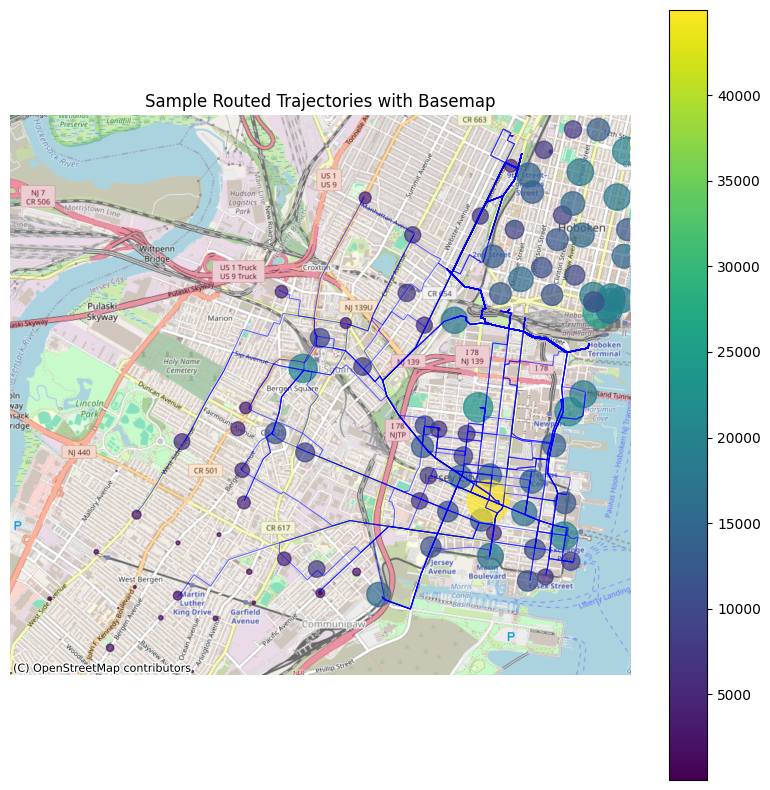

In [25]:
import matplotlib.pyplot as plt
import contextily as ctx

# Convert to Web Mercator (required for basemap)
routes_web = routes_gdf.to_crs(epsg=3857)

# Create plot
fig, ax = plt.subplots(figsize=(10, 10))

# Plot routes (sample to avoid clutter)
routes_web.sample(200).plot(
    ax=ax,
    linewidth=0.8,
    alpha=0.6,
    color="blue"
)

# Plot stations
stations_web.plot(
    ax=ax,
    column="trip_count",
    cmap="viridis",
    markersize=stations_web["trip_count"] / 50,
    alpha=0.7,
    legend=True
)

# Set bounds (VERY IMPORTANT)
ax.set_xlim(routes_web.total_bounds[[0, 2]])
ax.set_ylim(routes_web.total_bounds[[1, 3]])

# Add basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.OpenStreetMap.Mapnik
)

# Final formatting
ax.set_title("Sample Routed Trajectories with Basemap")
ax.axis("off")

plt.show()

## Interpretation of Routed Trajectories

The routed trajectories follow the underlying bicycle network and represent estimated paths between trip origins and destinations.

The visualization shows that routes are constrained by the street network, with many trajectories following major corridors and intersections.

Rather than indicating pure spatial clustering, the observed patterns reflect the combined effect of network topology, station locations, and routing assumptions.

The inclusion of a basemap provides essential geographic context, enabling more accurate interpretation of spatial patterns compared to visualizations without background reference.

## Introducing Route Variability

Shortest-path routing assumes that all users follow identical optimal routes, which may not reflect real-world behavior.

To simulate variability, a subset of trips is routed via randomly selected intermediate nodes. This introduces alternative paths and reduces unrealistic route overlap.

In [ ]:
import random
import networkx as nx

variable_routes = []

for o, d in zip(orig_nodes, dest_nodes):
    try:
        if random.random() < 0.3:
            mid = random.choice(list(G.nodes))
            r1 = nx.shortest_path(G, o, mid, weight="length")
            r2 = nx.shortest_path(G, mid, d, weight="length")
            route = r1 + r2[1:]
        else:
            route = nx.shortest_path(G, o, d, weight="length")
        
        variable_routes.append(route)
    except:
        variable_routes.append(None)

In [ ]:
from shapely.geometry import LineString

variable_geometries = []
invalid_var_routes = 0

for route in variable_routes:
    if route is None or len(route) < 2:
        variable_geometries.append(None)
        invalid_var_routes += 1
        continue
    
    try:
        coords = [(G.nodes[node]["x"], G.nodes[node]["y"]) for node in route]
        variable_geometries.append(LineString(coords))
    except:
        variable_geometries.append(None)
        invalid_var_routes += 1

print("Invalid variable routes:", invalid_var_routes)

In [ ]:
import geopandas as gpd

var_routes_gdf = route_subset.copy()
var_routes_gdf["geometry"] = variable_geometries

var_routes_gdf = var_routes_gdf.dropna(subset=["geometry"])

var_routes_gdf = gpd.GeoDataFrame(var_routes_gdf, geometry="geometry", crs="EPSG:4326")

print(var_routes_gdf.head())

In [ ]:
print("Valid variable trajectories:", len(var_routes_gdf))
print("Dropped variable trajectories:", len(route_subset) - len(var_routes_gdf))

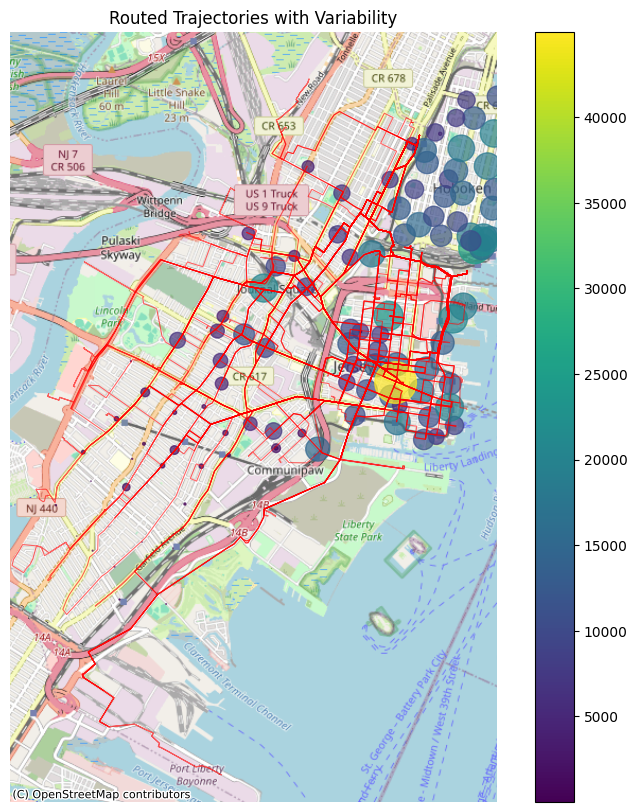

In [27]:
import matplotlib.pyplot as plt
import contextily as ctx

var_routes_web = var_routes_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10,10))

var_routes_web.sample(200).plot(
    ax=ax,
    linewidth=0.8,
    alpha=0.6,
    color="red"
)

# Plot stations
stations_web.plot(
    ax=ax,
    column="trip_count",
    cmap="viridis",
    markersize=stations_web["trip_count"] / 50,
    alpha=0.7,
    legend=True
)

ax.set_xlim(var_routes_web.total_bounds[[0, 2]])
ax.set_ylim(var_routes_web.total_bounds[[1, 3]])

ctx.add_basemap(ax,source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_title("Routed Trajectories with Variability")
ax.axis("off")

plt.show()

## Effect of Route Variability

Introducing variability results in more diverse route patterns compared to the baseline shortest-path routing.

Some trajectories deviate from the most direct path, reflecting more realistic user behavior where individuals may choose alternative routes due to personal preferences, traffic conditions, or environmental factors.

This reduces the tendency for all trips to follow identical shortest paths and produces a more behaviorally plausible set of simulated trajectories.

## Routing Tools, Assumptions, and Procedures

Trip trajectories were generated using a bicycle network extracted from OpenStreetMap via OSMnx. The routing workflow used NetworkX shortest-path computations with edge length as the routing weight.

Because the available dataset contains only trip origins and destinations, actual trajectories were approximated using network-based routing assumptions. A baseline shortest-path approach was used first, after which route variability was introduced by routing a subset of trips through randomly selected intermediate nodes.

Due to computational constraints, routing was not performed on the full yearly dataset. Instead, a representative sample of 100,000 trips was selected, and a routing subset of 10,000 trips was used for trajectory generation.

The routing analysis was performed on a Jersey City bicycle network, since the spatial extent of the dataset corresponds primarily to Jersey City rather than the full New York City area.

## Conclusion

So, finally this task demonstrates how origin–destination trip data can be transformed into realistic route trajectories using a network-based routing approach.

The results show that incorporating network constraints and route variability provides a more accurate representation of mobility patterns compared to simple straight-line approximations.

While shortest-path routing provides a useful baseline, introducing variability is essential for capturing more realistic user behavior in mobility modelling.

Future work could incorporate more advanced routing models, such as stochastic routing or real-time traffic conditions.